In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# CSV ફાઈલ લોડ કરો
df = pd.read_csv('/content/pubg_classification_dataset.csv')
print("Shape of dataset:", df.shape)
df.head()

Shape of dataset: (200000, 11)


,Id,matchId,kills,assists,damageDealt,walkDistance,rideDistance,weaponsAcquired,heals,boosts,winStatus
0,player_0,match_913,2.0,0,334.6918262685328,726.981088,1276.075115,6.0,4,0,0
1,player_1,match_205,1.0,2,200.2427921035029,41.052799,440.054659,5.0,0,0,0
2,player_2,match_2254,0.0,0,99.35643214976429,NaN,1578.690352,5.0,1,2,0
3,player_3,match_2007,0.0,0,23.848229889470396,812.134413,291.679938,NaN,3,2,0
4,player_4,match_1829,3.0,0,452.07566846622495,5.444907,607.621138,4.0,0,1,1


In [3]:
# 1. Invalid String Values (જેમ કે 'Unknown', 'None') ને NaN માં કન્વર્ટ કરો
df.replace(['Unknown', 'None'], np.nan, inplace=True)

# 2. કૉલમ્સને ન્યુમેરિક ડેટા ટાઈપમાં કન્વર્ટ કરો
num_cols = ['kills', 'assists', 'damageDealt', 'walkDistance', 'rideDistance', 'weaponsAcquired', 'heals', 'boosts']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 3. Negative / Invalid વૅલ્યૂઝ દૂર કરો (અથવા Correct કરો)
df.loc[df['kills'] < 0, 'kills'] = np.nan
df.loc[df['walkDistance'] < 0, 'walkDistance'] = np.nan

# 4. Missing / Null Values ચેક કરો
print("Missing values count per column:")
print(df.isnull().sum())

# 5. Null Values ને Median થી Impute કરો
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

print("\nAfter Cleaning Null Values:")
print(df.isnull().sum())

Missing values count per column:
Id                     0
matchId                0
kills              13846
assists                0
damageDealt        11900
walkDistance       13671
rideDistance           0
weaponsAcquired    11980
heals                  0
boosts                 0
winStatus              0
dtype: int64

After Cleaning Null Values:
Id                 0
matchId            0
kills              0
assists            0
damageDealt        0
walkDistance       0
rideDistance       0
weaponsAcquired    0
heals              0
boosts             0
winStatus          0
dtype: int64


/tmp/ipykernel_1468/1440236666.py:19: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


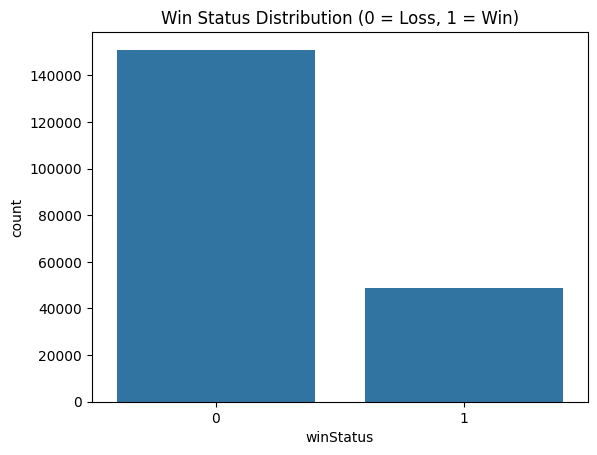

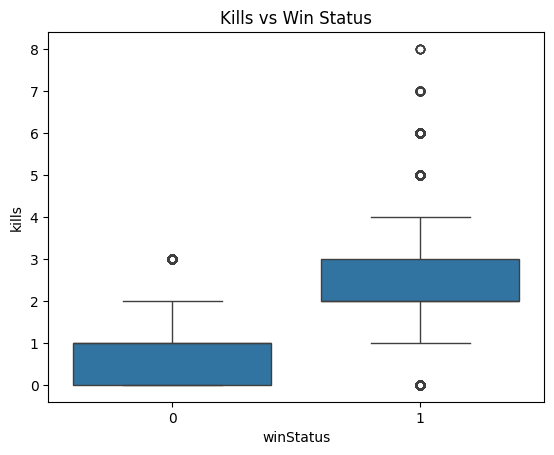

In [4]:
# Target Variable Distribution
sns.countplot(x='winStatus', data=df)
plt.title("Win Status Distribution (0 = Loss, 1 = Win)")
plt.show()

# Kills vs Win Status
sns.boxplot(x='winStatus', y='kills', data=df)
plt.title("Kills vs Win Status")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Features અને Target અલગ કરો
X = df[num_cols]
y = df['winStatus']

# Train and Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

Training shape: (160000, 8)
Testing shape: (40000, 8)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Model 1: Logistic Regression
lr_model = LogisticRegression()
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

print("--- Logistic Regression Performance ---")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr))

# Model 2: Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("--- Random Forest Performance ---")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

--- Logistic Regression Performance ---
Accuracy: 0.972275
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     30204
           1       0.96      0.93      0.94      9796

    accuracy                           0.97     40000
   macro avg       0.97      0.96      0.96     40000
weighted avg       0.97      0.97      0.97     40000

--- Random Forest Performance ---
Accuracy: 0.9741
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     30204
           1       0.98      0.91      0.95      9796

    accuracy                           0.97     40000
   macro avg       0.98      0.95      0.96     40000
weighted avg       0.97      0.97      0.97     40000



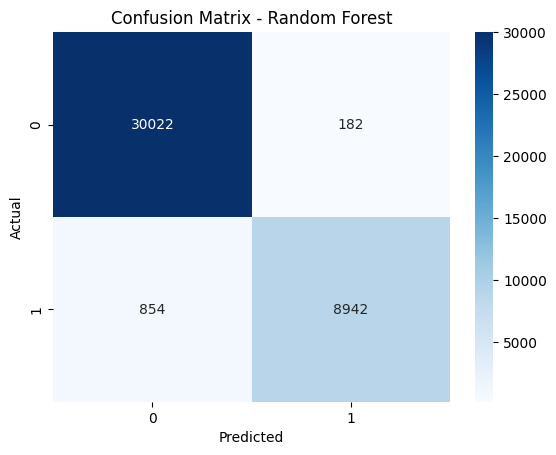

In [8]:
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

/tmp/ipykernel_1468/3787849393.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')


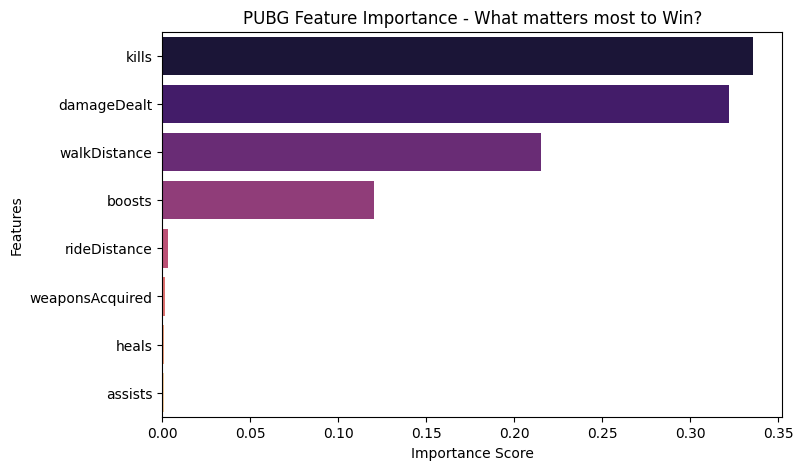

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Feature Importances મેળવો
importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': num_cols, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# Graph દોરો
plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='magma')
plt.title('PUBG Feature Importance - What matters most to Win?')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [10]:
# custom input: [kills, assists, damageDealt, walkDistance, rideDistance, weaponsAcquired, heals, boosts]
sample_player = [[4, 1, 520.0, 1800.5, 1200.0, 6, 3, 2]]

# Prediction અને Probability
pred = rf_model.predict(sample_player)
prob = rf_model.predict_proba(sample_player)

if pred[0] == 1:
    print(f"Prediction: WIN (Chicken Dinner! 🏆)")
    print(f"Win Probability: {prob[0][1]*100:.2f}%")
else:
    print(f"Prediction: LOSS ❌")
    print(f"Win Probability: {prob[0][1]*100:.2f}%")

Prediction: WIN (Chicken Dinner! 🏆)
Win Probability: 99.60%


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


In [11]:
import joblib

# Model અને Scaler સેવ કરો
joblib.dump(rf_model, 'pubg_rf_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model and Scaler successfully saved as 'pubg_rf_model.pkl' and 'scaler.pkl'!")

Model and Scaler successfully saved as 'pubg_rf_model.pkl' and 'scaler.pkl'!
